In [19]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# ==========================================
# STEP 1: The Schema-Enforced Load
# ==========================================
FOLDER_PATH = '../../data/raw/tracebench/AN_Data_corruptBlk_r_00FDN_30C_1to19B_0to120INT_15RT_5WT/'

# We explicitly define the exact columns based on the dataset documentation
EVENT_COLS = ['TaskID', 'TID', 'OpName', 'StartTime', 'EndTime', 'HostAddress', 'HostName', 'Agent', 'Description']
EDGE_COLS = ['TaskID', 'FatherTID', 'FatherStartTime', 'ChildTID']

# header=0 tells Pandas to ignore the broken headers in the file
# names=... forces Pandas to use our perfect headers
# index_col=False explicitly forbids Pandas from shifting the columns!
df_events = pd.read_csv(FOLDER_PATH + 'event.csv', header=0, names=EVENT_COLS, index_col=False)
df_edges = pd.read_csv(FOLDER_PATH + 'edge.csv', header=0, names=EDGE_COLS, index_col=False)

# Clean hidden spaces just to be perfectly safe
df_events['TaskID'] = df_events['TaskID'].astype(str).str.strip()
df_edges['TaskID'] = df_edges['TaskID'].astype(str).str.strip()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13472\1685752332.py:17: ParserWarning: Length of header or names does not match length of data. This leads to a loss of data with index_col=False.
  df_events = pd.read_csv(FOLDER_PATH + 'event.csv', header=0, names=EVENT_COLS, index_col=False)


In [20]:
# ==========================================
# STEP 2: Isolate the Task
# ==========================================
TARGET_TASK = '0115DB0FAF9DE3D7'

# Because the columns are fixed, we can go back to clean, standard Pandas filtering!
events_filtered = df_events[df_events['TaskID'] == TARGET_TASK]
edges_filtered = df_edges[df_edges['TaskID'] == TARGET_TASK]

print(f"Isolated Task: {TARGET_TASK}")
print(f"Nodes found: {len(events_filtered)} | Edges found: {len(edges_filtered)}")

Isolated Task: 0115DB0FAF9DE3D7
Nodes found: 110 | Edges found: 43


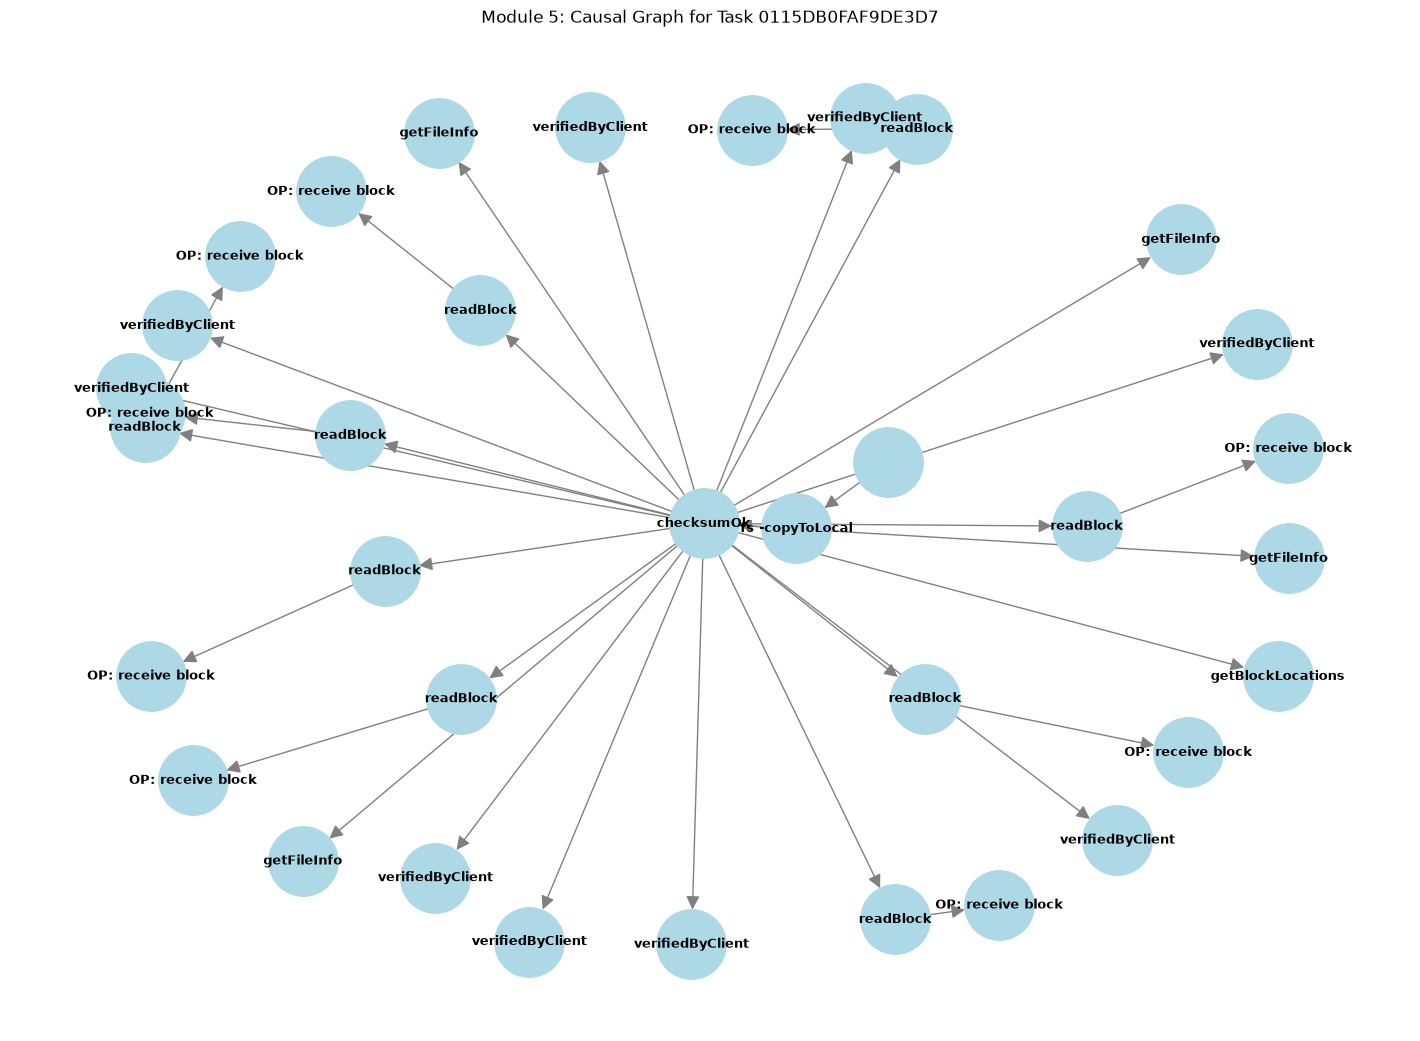

In [21]:
# ==========================================
# STEP 3: Build and Draw the DAG
# ==========================================
if len(events_filtered) == 0 or len(edges_filtered) == 0:
    print("❌ ERROR: Still 0? We have a bigger problem.")
else:
    G = nx.DiGraph()
    
    # Add Nodes
    for index, row in events_filtered.iterrows():
        G.add_node(str(row['TID']).strip(), label=str(row['OpName']).strip())
        
    # Add Edges
    for index, row in edges_filtered.iterrows():
        G.add_edge(str(row['FatherTID']).strip(), str(row['ChildTID']).strip())
        
    # Draw Graph
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, k=0.8, iterations=100)
    nx.draw(G, pos, 
            labels=nx.get_node_attributes(G, 'label'), 
            with_labels=True, 
            node_color='lightblue', 
            edge_color='gray', 
            node_size=2500, 
            font_size=9, 
            font_weight='bold',
            arrows=True,
            arrowsize=20)
    
    plt.title(f"Module 5: Causal Graph for Task {TARGET_TASK}")
    plt.show()